# 1.1. The Simplest Graph
##Let's build a simple graph with 3 nodes and one conditional edge. 

![Screenshot 2024-08-20 at 3.11.22 PM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dba5f465f6e9a2482ad935_simple-graph1.png)

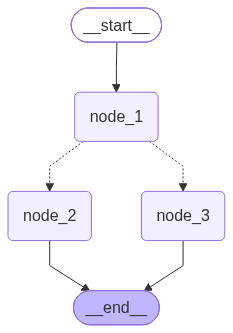

Invocation - 1 
---Node 1---
---Node 3---
Invocation - 2 
---Node 1---
---Node 2---


{'graph_state': 'Hi, this is Lance. I am happy!'}

In [9]:
from dotenv import load_dotenv
from typing_extensions import TypedDict
import random
from typing import Literal
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Define Nodes
class State(TypedDict):
    graph_state: str

def node_1(state):
    print("---Node 1---")
    return {"graph_state": state['graph_state'] +" I am"}

def node_2(state):
    print("---Node 2---")
    return {"graph_state": state['graph_state'] +" happy!"}

def node_3(state):
    print("---Node 3---")
    return {"graph_state": state['graph_state'] +" sad!"}

# Define Conditional Edge
def decide_mood(state) -> Literal["node_2", "node_3"]:
    
    # Often, we will use state to decide on the next node to visit
    user_input = state['graph_state'] 
    
    # Here, let's just do a 50 / 50 split between nodes 2, 3
    if random.random() < 0.5:

        # 50% of the time, we return Node 2
        return "node_2"
    
    # 50% of the time, we return Node 3
    return "node_3"

# Build graph
builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

# Invokation - 1 
print("Invocation - 1 ")
graph.invoke({"graph_state" : "Hi, this is Lance."})

# Invokation - 2 
print("Invocation - 2 ")
graph.invoke({"graph_state" : "Hi, this is Lance."})

# 1.2. Chain
####    Concepts - 
 1. Chat **Messages** as our graph state, 
 2. Chat Models in graph nodes, 
 3. Binding Tools to out chat models, 
 4. Executing tools Call in graph nodes 
 
![Screenshot 2024-08-21 at 9.24.03 AM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dd607b08df5e1101_chain1.png)

Result: content='One of the best places to see orcas in the United States is the Pacific Northwest, particularly around the San Juan Islands in Washington State. These islands are known for regular sightings of orcas, especially during the months from April to October. The orcas in this area are typically divided into two groups: the resident pods that primarily eat fish and the transient pods that hunt marine mammals.\n\nAnother excellent location is the waters around the Salish Sea, which includes parts of both the US and Canada, where orcas are frequently spotted. In addition to boat tours, you can sometimes see orcas from the shore at places like Lime Kiln Point State Park on San Juan Island, often referred to as "Whale Watch Park."\n\nIf you’re interested in other regions, areas like Monterey Bay in California and parts of Alaska, such as the Kenai Fjords, also offer opportunities to see orcas, although sightings may be less predictable compared to the San Juan Islands.' additiona

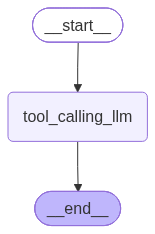

In [2]:
from dotenv import load_dotenv
from pprint import pprint

from langchain_core.messages import AIMessage, HumanMessage, AnyMessage
# from langchain_core.messages import AnyMessage

from langgraph.graph.message import add_messages
from langgraph.graph import MessagesState

from pyclbr import Class

from typing_extensions import TypedDict
from typing import Annotated

#8 Our graph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END


#1. ChaT Messages
"""1.1.simple-graph.ipynb"""
messages = [AIMessage(content=f"So you said you were researching ocean mammals?", name="Model")]
messages.append(HumanMessage(content=f"Yes, that's right.",name="Lance"))
messages.append(AIMessage(content=f"Great, what would you like to learn about.", name="Model"))
messages.append(HumanMessage(content=f"I want to learn about the best place to see Orcas in the US.", name="Lance"))

# for m in messages:
#     m.pretty_print()

#2. Chat Model
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o")
result = llm.invoke(messages)

print(f"Result: {result}, Type: {type(result)}")
print (f"Result content: {result.content}")
pprint(f" Result Metadata: {result.response_metadata}")

#3. Tools (Function Calling) Bindings with Chat Models 
def multiply(a: int, b: int) -> int:
    return a * b

def add(a: int, b: int) -> int:
    return a + b

llm_with_tools = llm.bind_tools([multiply, add]) #Binds the tools to the LLM

# Tool call with the LLM
tool_call = llm_with_tools.invoke([HumanMessage(content=f"Please multiply 5 and 6.", name = "Pushpam")])

pprint(tool_call.pretty_print())
pprint(tool_call.tool_calls)


# 4. Define Message as state and use it in a graph
class MessageState(TypedDict):
    messages: list[AnyMessage]


#5. Reducer Function - to append the new message to the existing messages in the state
class MessageState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

class MessagesState(MessagesState):
    #add any key needed beyonf messages
    pass

#Initial state
initial_messages = [AIMessage(content="Hello! How can I assist you?", name="Model"),
                    HumanMessage(content="I'm looking for information on marine biology.", name="Pushpam")
                   ]
# New message to add
new_message = AIMessage(content="Sure, I can help with that. What specifically are you interested in?", name="Model")
# Test
add_messages(initial_messages , new_message)

#8 Our graph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
    
# Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_edge(START, "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [3]:
tool_call.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  multiply (call_IJ38UdgD1TYb6Bqo108nIOWZ)
 Call ID: call_IJ38UdgD1TYb6Bqo108nIOWZ
  Args:
    a: 5
    b: 6


In [4]:
tool_call.tool_calls

[{'name': 'multiply',
  'args': {'a': 5, 'b': 6},
  'id': 'call_IJ38UdgD1TYb6Bqo108nIOWZ',
  'type': 'tool_call'}]

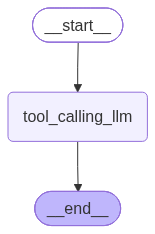

In [10]:


from pyclbr import Class

from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
from langgraph.graph import MessagesState
#8 Our graph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# 4. Define Message as state and use it in a graph
class MessageState(TypedDict):
    messages: list[AnyMessage]


#5. Reducer Function - to append the new message to the existing messages in the state
class MessageState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

class MessagesState(MessagesState):
    #add any key needed beyonf messages
    pass

#Initial state
initial_messages = [AIMessage(content="Hello! How can I assist you?", name="Model"),
                    HumanMessage(content="I'm looking for information on marine biology.", name="Pushpam")
                   ]
# New message to add
new_message = AIMessage(content="Sure, I can help with that. What specifically are you interested in?", name="Model")
# Test
add_messages(initial_messages , new_message)

#8 Our graph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
    
# Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_edge(START, "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
messages = graph.invoke({"messages": HumanMessage(content="Hello!")})
for m in messages['messages']:
    m.pretty_print()

messages = graph.invoke({"messages": HumanMessage(content="Multiply 2 and 3")})
for m in messages['messages']:
    m.pretty_print()